# 3 · Calibration against national accounts, and wage shocks

MarxKapital calibrates its departments from Portuguese national accounts (INE) or from the European Commission's AMECO database. **Everything in this notebook uses the synthetic defaults and runs offline.** Real data are opt-in, as shown at the end.

Calibration maps national-accounts aggregates to Marxian categories: compensation of employees → variable capital `V`, gross operating surplus → surplus value `S`, the capital stock → constant capital `C`. From these follow `e = S/V`, `k = C/V` and `r = S/(C + V)`.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random, DataFrames
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. Portugal, INE structure (19 sectors)

`calibrate_portugal_model` returns a `CalibratedParameters` with per-sector `C`, `V`, `e`, `k`, `r`, the technical matrix `A`, labor coefficients `l` and reinvestment shares. `aggregation` can be `:detailed` (19 sectors), `:mean` (10) or `:macro` (3).

In [2]:
params = calibrate_portugal_model(year = 2022)

CALIBRATION FOR PORTUGAL (INE)  |  Year: 2022  |  Aggregation: detailed  |  Source: synthetic

🔬 Generating synthetic data for Portugal (2022)...

🔄 Processing supply and use tables...

📐 Estimating parameters...


  ✓ mean e: 1.02 | mean k: 10.59 | mean r: 13.4%



✅ CALIBRATION COMPLETE — 19 sectors | GDP: €181.0 bn


CalibratedParameters(19, ["Agriculture, forestry and fishing", "Mining and quarrying", "Manufacturing", "Electricity, gas, steam", "Water supply, sewerage, waste", "Construction", "Wholesale and retail trade", "Transportation and storage", "Accommodation and food service", "Information and communication", "Financial and insurance activities", "Real estate activities", "Professional, scientific and technical", "Administrative and support", "Public administration", "Education", "Human health and social work", "Arts, entertainment and recreation", "Other service activities"], ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N", "O", "P", "Q", "R", "S"], [7000.0, 4000.0, 33300.0, 25600.0, 7200.0, 12750.0, 22800.0, 27300.0, 12960.0, 17000.0, 17250.0, 285000.0, 12000.0, 11400.0, 42500.0, 27000.0, 37500.0, 4400.0, 5700.0], [979.9999999999999, 320.0, 9620.0, 1120.0, 540.0, 5100.0, 9120.0, 3900.0, 4176.0, 4675.0, 4370.0, 2850.0, 7440.0, 6175.0, 12240.0, 10125.0, 10500.0, 1320.

In [3]:
DataFrame(sector = params.sector_names, e = round.(params.e, digits = 2),
          k = round.(params.k, digits = 2), r = round.(params.r, digits = 3))

Row,sector,e,k,r
,String,Float64,Float64,Float64
1,"Agriculture, forestry and fishing",1.63,7.14,0.2
2,Mining and quarrying,1.2,12.5,0.089
3,Manufacturing,0.73,3.46,0.164
4,"Electricity, gas, steam",1.43,22.86,0.06
5,"Water supply, sewerage, waste",1.0,13.33,0.07
6,Construction,0.57,2.5,0.162
7,Wholesale and retail trade,0.92,2.5,0.262
8,Transportation and storage,0.76,7.0,0.095
9,Accommodation and food service,0.59,3.1,0.143


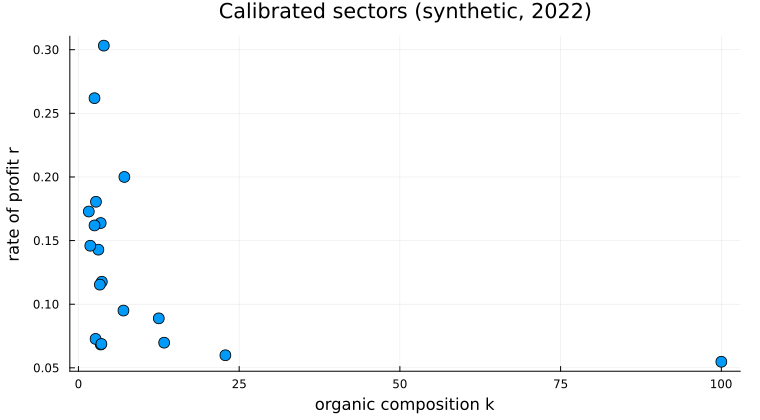

In [4]:
scatter(params.k, params.r, xlabel = "organic composition k", ylabel = "rate of profit r",
        legend = false, title = "Calibrated sectors (synthetic, 2022)", markersize = 6)

## 2. Validating the calibration

`validate_calibrated_profit_rates` checks the calibrated profit rates against the wage–profit frontier of the calibrated `A`: whether the average rate is feasible (below `R_max`), how dispersed the rates are, and which sectors are problematic. It prints a report and returns a quality score in percent.

PROFIT RATE VALIDATION

Base year: 2022  |  Sectors: 19

📊 STATISTICS
----------------------------------------------------------------------
  Mean:     13.39%
  Median:   11.76%
  Min/Max:  5.48% / 30.32%
  Standard deviation: 6.96pp
  Coef. of variation: 0.52

⚙️  Theoretical maximum rate (R_max): 105.27%

🔍 TEST 1: Feasibility of the Mean Rate
  ✓ Feasible, margin: 87.3%

🔍 TEST 2: Sectoral Feasibility
  ✓ All sectors within the bound

🔍 TEST 3: Dispersion (CV = 0.52)
  ⚠️  Moderate
  Abnormally high profits (>2σ):
    • Financial and insurance activities: 30.3%

🔍 TEST 4: Consistency
  mean k = 10.59  →  implied e = 1.55
  ✓ Reasonable

🔍 TEST 5: Position on the Frontier: 12.7% of R_max
  → Low profit rate


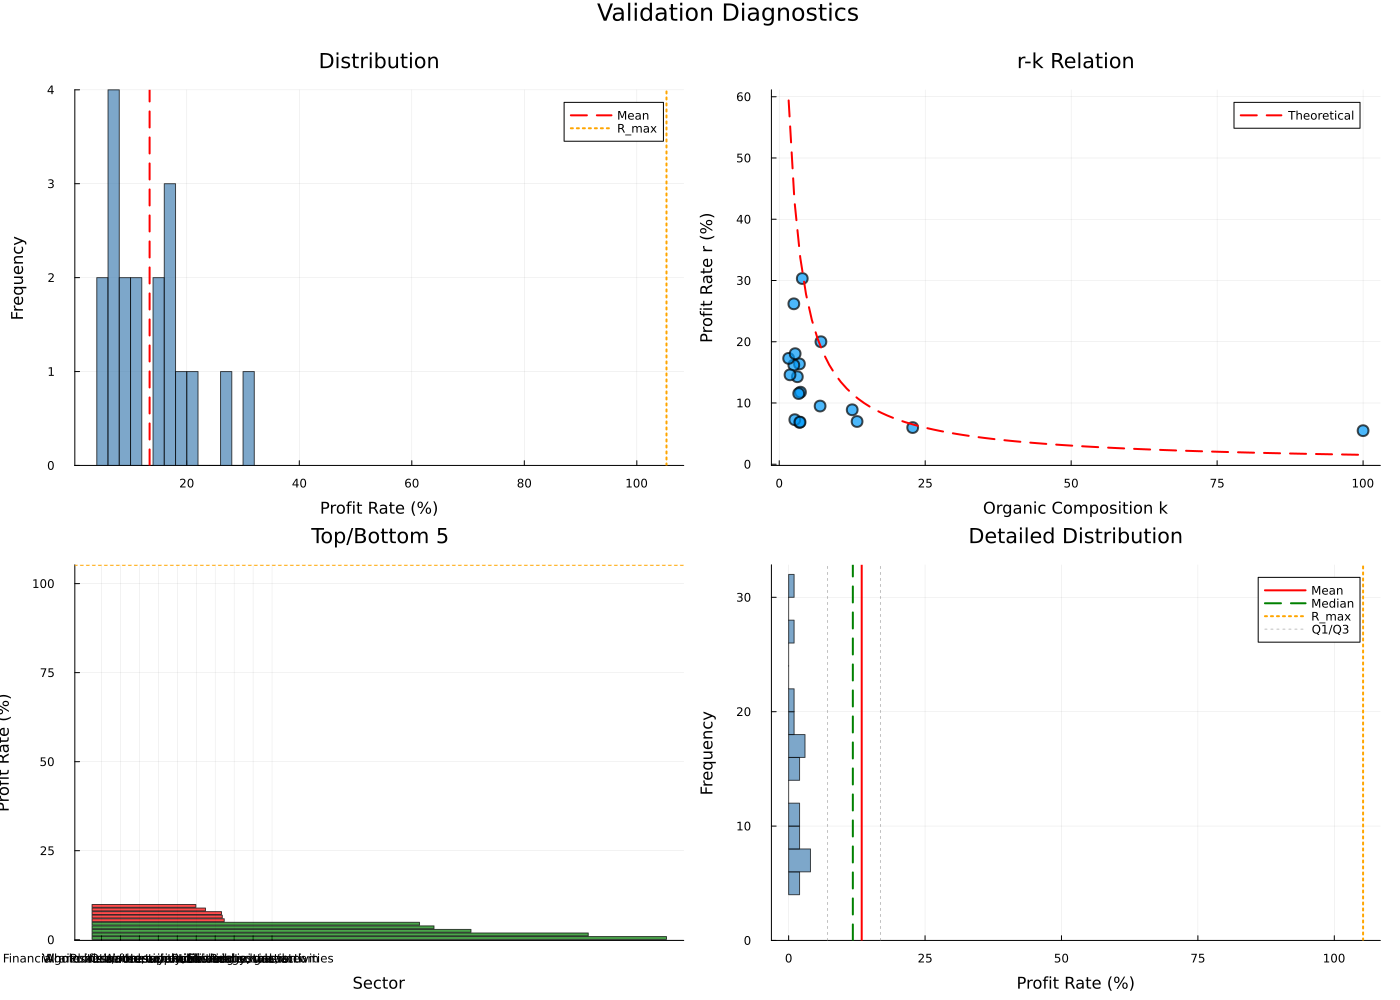


----------------------------------------------------------------------


  FINAL SCORE: 60.0%  ⚠️  ACCEPTABLE



In [5]:
validation = validate_calibrated_profit_rates(params);

In [6]:
(R_max = validation.R_max, r_mean = validation.r_mean, cv = validation.cv,
 score = validation.score, problematic = validation.problem_sectors)

(R_max = 1.052748440481201, r_mean = 0.13389886808386964, cv = 0.5200731282877861, score = 60.0, problematic = Int64[])

## 3. AMECO: any country, three macro-sectors

`calibrate_with_ameco_v2(country; method)` fetches AMECO series and calibrates three macro-sectors. `method = :synthetic` generates plausible series offline. The default, `:auto`, tries the official SDMX API first. Country names are in Portuguese (`list_ameco_countries()` lists them).

In [7]:
params_pt, data_pt = calibrate_with_ameco_v2("Portugal", year = 2022, method = :synthetic)
(sectors = params_pt.sector_names, e = params_pt.e, k = params_pt.k, r = params_pt.r)


🔬 Generating synthetic AMECO data for PT...


  ✓ 28 years (1995-2022) | mean GDP 193.1 bn | mean unemployment 6.8%

CALIBRATION WITH AMECO DATA — Portugal | Year: 2022
Source: AMECO (synthetic)

📊 Data (2022): GDP 234.0 bn | Employment 4.9 M | Stock K 810.1 bn

📐 Marxian parameters:
  Primary: e=0.59 k=6.66 r=7.71%
  Secondary: e=0.59 k=4.84 r=10.1%
  Tertiary: e=0.59 k=7.18 r=7.21%

✅ CALIBRATION COMPLETE — mean e 0.59 | mean r 8.34%



(sectors = ["Primary", "Secondary", "Tertiary"], e = [0.5901775836384051, 0.5901775836384051, 0.590177583638405], k = [6.657986788770359, 4.842172210014807, 7.183617324725913], r = [0.07706693677035838, 0.10102023056196581, 0.07211695760201879])

INTERNATIONAL COMPARISON — AMECO | Year: 2022
Countries: Portugal, Spain, Italy, Greece

🌍 Portugal...

🔬 Generating synthetic AMECO data for PT...
  ✓ 28 years (1995-2022) | mean GDP 193.1 bn | mean unemployment 7.0%

CALIBRATION WITH AMECO DATA — Portugal | Year: 2022
Source: AMECO (synthetic)

📊 Data (2022): GDP 234.0 bn | Employment 4.9 M | Stock K 810.1 bn

📐 Marxian parameters:
  Primary: e=0.59 k=6.66 r=7.71%
  Secondary: e=0.59 k=4.84 r=10.1%
  Tertiary: e=0.59 k=7.18 r=7.21%

✅ CALIBRATION COMPLETE — mean e 0.59 | mean r 8.34%


🌍 Spain...

🔬 Generating synthetic AMECO data for ES...
  ✓ 28 years (1995-2022) | mean GDP 1155.4 bn | mean unemployment 13.1%

CALIBRATION WITH AMECO DATA — Spain | Year: 2022
Source: AMECO (synthetic)

📊 Data (2022): GDP 1400.0 bn | Employment 20.5 M | Stock K 4847.0 bn

📐 Marxian parameters:
  Primary: e=0.59 k=6.66 r=7.71%
  Secondary: e=0.59 k=4.26 r=11.22%
  Tertiary: e=0.59 k=7.48 r=6.96%

✅ CALIBRATION COMPLETE — mean e 0.59 | mean r 8.63%


🌍

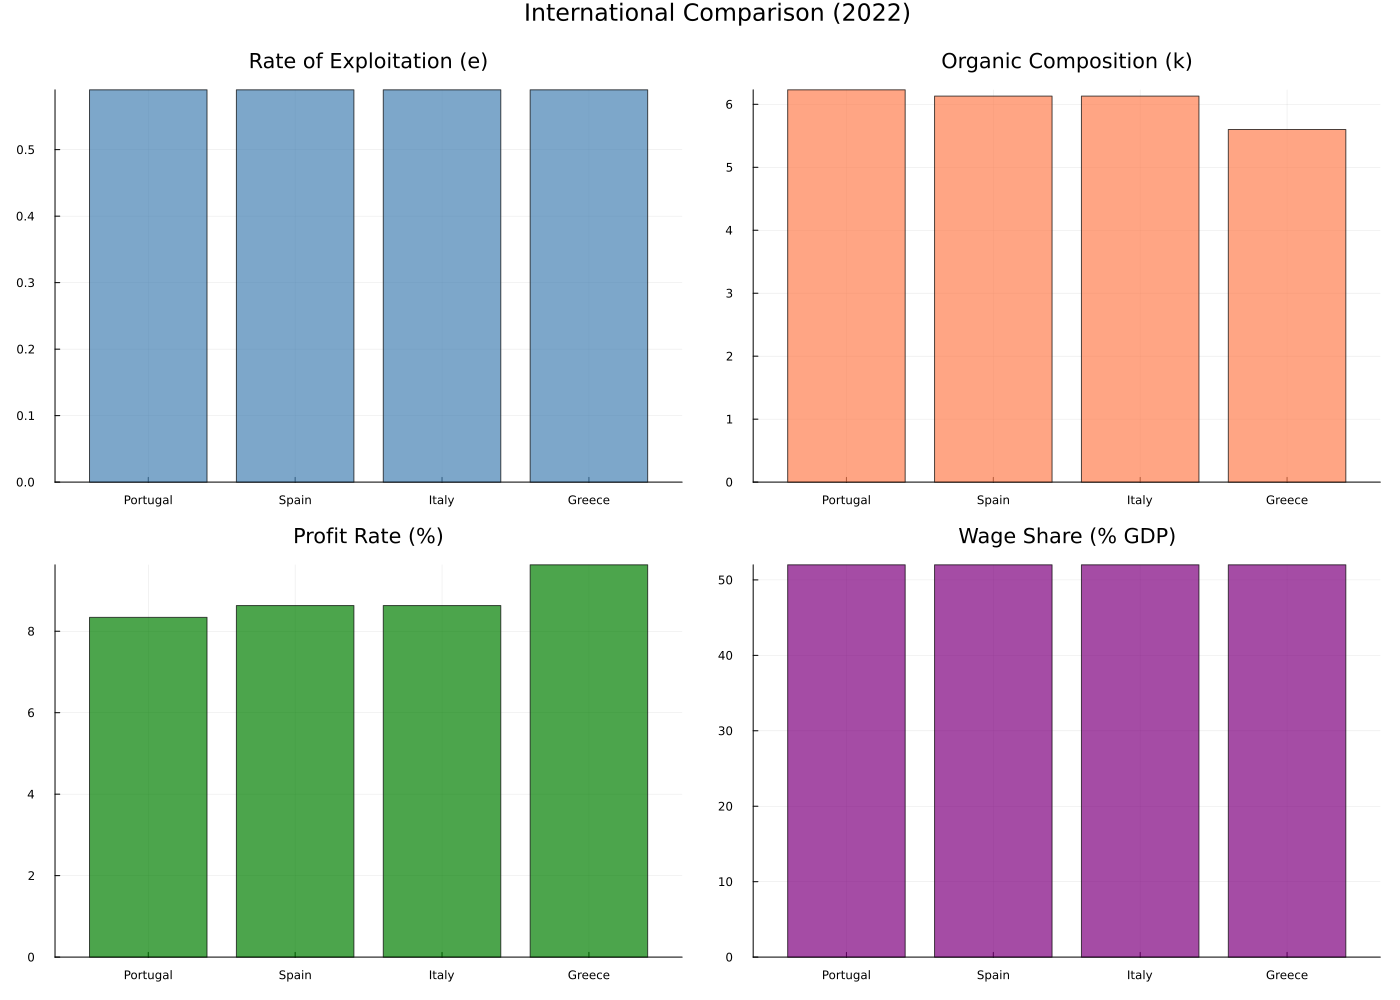

Row,Country,GDP,Exploitation_Rate,Organic_Composition,Profit_Rate,Wage_Share
,String,Float64,Float64,Float64,Float64,Float64
1,Portugal,234.0,0.59,6.23,8.34,52.0
2,Spain,1400.0,0.59,6.13,8.63,52.0
3,Italy,2000.0,0.59,6.13,8.63,52.0
4,Greece,215.0,0.59,5.6,9.63,52.0


In [8]:
comparison = compare_ameco_countries(["Portugal", "Spain", "Italy", "Greece"], year = 2022)
comparison.table

The synthetic AMECO series only exercise the pipeline offline; use `method = :auto` or `:sdmx` for real AMECO data. With the default fixed sectoral weights (`sector_data = :fixed`), value added, wages and depreciation are split in the same proportions, so the rate of surplus value is the same in the three sectors and only the organic composition differs. `sector_data = :eurostat` uses real sectoral data instead.

`analyze_ameco_time_series` follows the aggregate rate of surplus value, organic composition, rate of profit and wage share over time.

TIME-SERIES ANALYSIS — Portugal | 2000-2022

🔬 Generating synthetic AMECO data for PT...
  ✓ 23 years (2000-2022) | mean GDP 199.5 bn | mean unemployment 6.9%


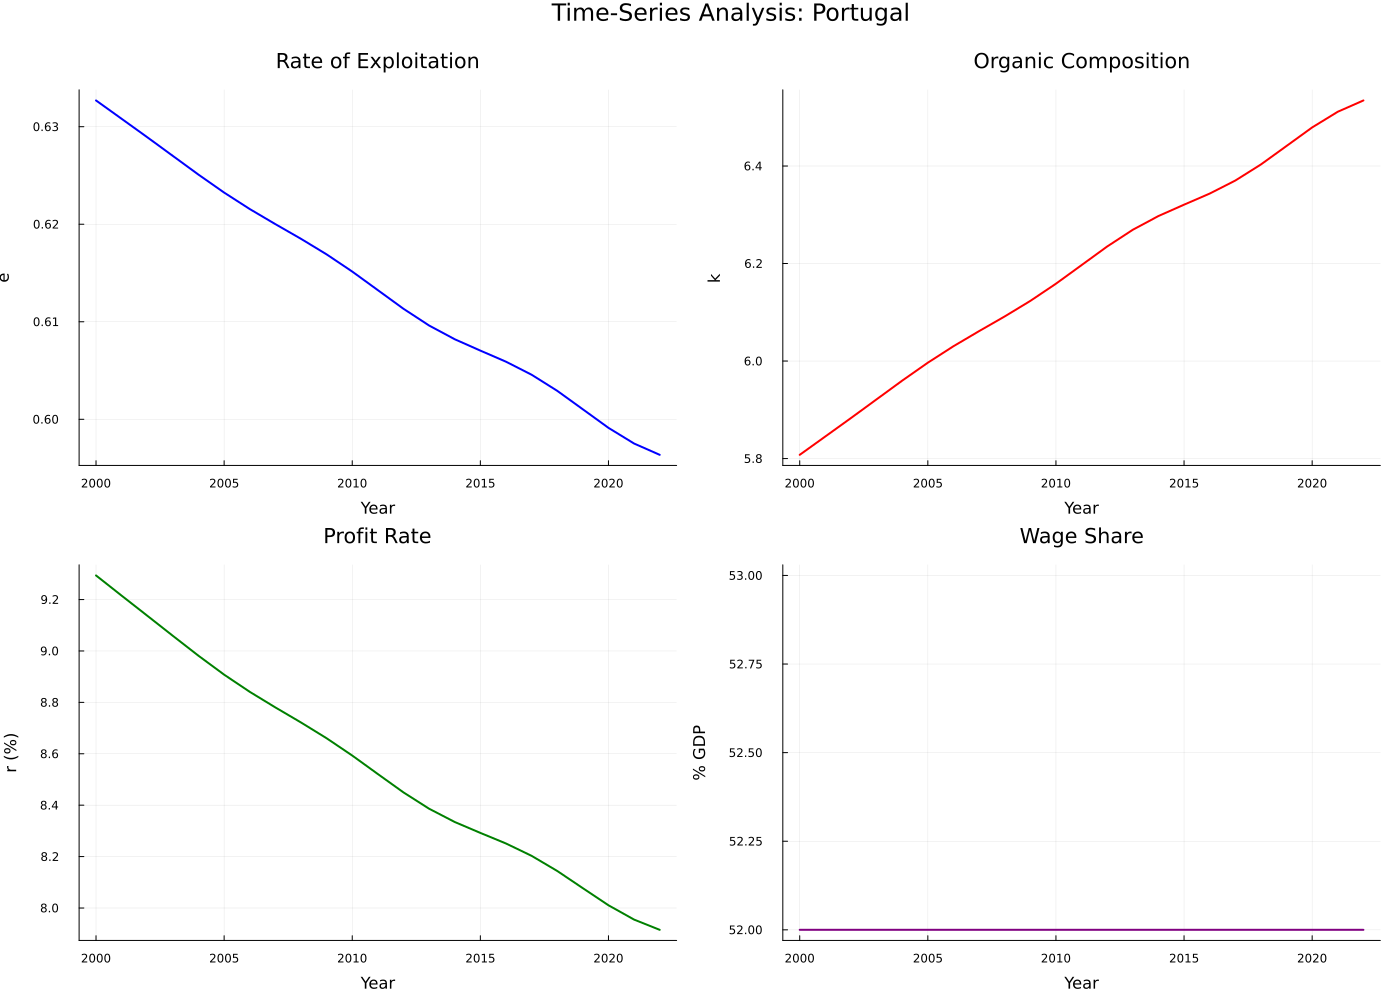


📈 PERIOD AVERAGES:


  e: 0.61 | k: 6.19 | r: 8.55% | wage share: 52.0%



In [9]:
series = analyze_ameco_time_series("Portugal", years = 2000:2022);

## 4. Wage-policy shocks

`simulate_wage_shock(depts, Δw)` runs a baseline and a shocked economy from the same matrix `A`. In the shock, variable capital rises by the factor `1 + Δw` while surplus value is unchanged in the short run, so the rate of surplus value falls by the same factor. It compares the mean sectoral rate of profit of the two runs (`impacto_r_*` are in percentage points). With `show_plot = true` it draws the two trajectories and their difference.

WAGE SHOCK SIMULATION — Δw = +10.0%

📈 PROFIT RATES


  Base:   initial 44.14%  →  final 50.16%
  Shock:  initial 42.92%  →  final 46.09%
  Impact: immediate -1.22pp | long run -4.07pp

💰 CAPITAL ACCUMULATION
  Base:   +8.1957620708e10%
  Shock:  +1.16735289048e10%


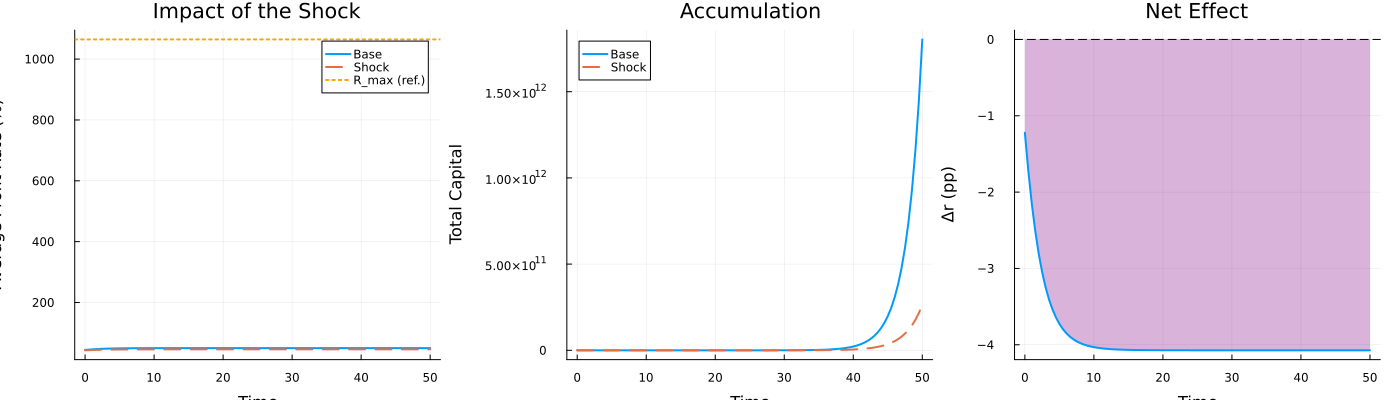

(r_base_final = 0.5016059885214315, r_shock_final = 0.46087677176784686, initial_r_impact = -1.222072650183359, final_r_impact = -4.07292167535846, R_max = 10.645911351606003, feasible = true)

In [10]:
Random.seed!(7)
depts = create_departments(6)
shock = simulate_wage_shock(depts, 0.10)

`compare_wage_shocks` runs several shocks and reports the final mean rate of profit of each, with the baseline (`0.0`) first.


🔬 Comparing 5 shock scenarios...

WAGE SHOCK SIMULATION — Δw = +-20.0%

📈 PROFIT RATES
  Base:   initial 44.14%  →  final 50.16%
  Shock:  initial 46.82%  →  final 61.34%
  Impact: immediate 2.67pp | long run 11.18pp

💰 CAPITAL ACCUMULATION
  Base:   +8.1957620708e10%
  Shock:  +1.8382216820246e13%

WAGE SHOCK SIMULATION — Δw = +-10.0%

📈 PROFIT RATES
  Base:   initial 44.14%  →  final 50.16%
  Shock:  initial 45.44%  →  final 55.13%
  Impact: immediate 1.3pp | long run 4.97pp

💰 CAPITAL ACCUMULATION
  Base:   +8.1957620708e10%
  Shock:  +9.009658269657e11%

WAGE SHOCK SIMULATION — Δw = +10.0%

📈 PROFIT RATES
  Base:   initial 44.14%  →  final 50.16%
  Shock:  initial 42.92%  →  final 46.09%
  Impact: immediate -1.22pp | long run -4.07pp

💰 CAPITAL ACCUMULATION
  Base:   +8.1957620708e10%
  Shock:  +1.16735289048e10%

WAGE SHOCK SIMULATION — Δw = +20.0%

📈 PROFIT RATES
  Base:   initial 44.14%  →  final 50.16%
  Shock:  initial 41.77%  →  final 42.69%
  Impact: immediate -2.38pp | lon

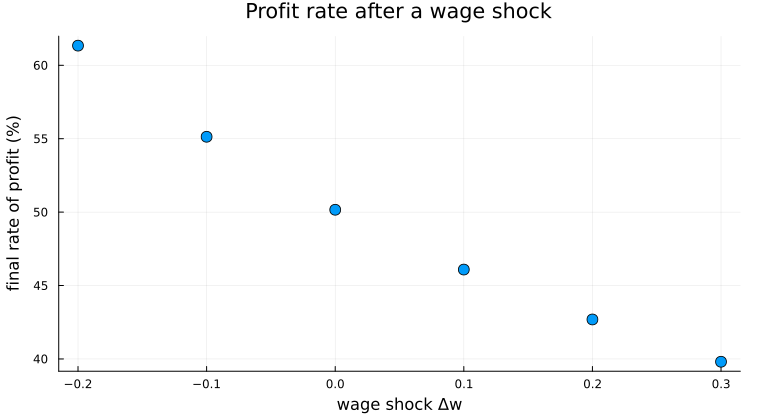

In [11]:
shocks = [-0.2, -0.1, 0.1, 0.2, 0.3]
res = compare_wage_shocks(depts, shocks)
plot(getfield.(res, :shock), 100 .* getfield.(res, :r_final), seriestype = :scatter,
     markersize = 6, legend = false, xlabel = "wage shock Δw",
     ylabel = "final rate of profit (%)", title = "Profit rate after a wage shock")

## 5. Real data (opt-in, needs network)

These calls are not run here. They replace the synthetic structure with Eurostat sectoral accounts and the real input–output matrix (`NAIO_10_CP1700`, domestic flows):

```julia
params_real = calibrate_portugal_model(ano = 2022, data_source = :eurostat)
params_real, dados = calibrate_with_ameco_v2("Portugal", ano = 2022, sector_data = :eurostat)
check_ameco_sdmx()          # check access to the AMECO SDMX API
check_eurostat_sectoral()   # check access to the Eurostat API
```

See `docs/LIMITATIONS.md` for the status of each data path.